# Plane-stress elasticity tomography: active scientific review


## 1. Problem

Infer 800 positive element Young moduli from noisy nodal displacements, known forces and a triangular mesh. The high-contrast material field is author-simulated; small-strain applicability must be checked independently of inverse quality.

We reconstruct 800 positive element Young moduli from 882 noisy nodal displacement components, known forces and a 441-node triangular mesh. This is an **author-defined simulated** acquisition, not measured material data. Modulus and force have arbitrary source units: choose length L0, force F0 and E0=F0/L0². All solver/prior equations operate on numerical coordinates x/L0 and numerical modulus E/E0.

The source-supported rectangular inclusion has 300:1 contrast. The final configurable nodal load is 0.00275 F0. A fresh independent original simulation has maximum absolute principal strain 0.002439<0.01. The original 2.75-load example reached 2.439, failing the small-strain premise; its result is retained only as a qualification diagnostic.

This notebook actively reconstructs all three prior variants and two additional TV strengths using local modules. Original and minimally qualified source results are separately identified; neither is relabeled ground truth. No cached result replaces a fresh computation.


## 2. Data

The fixed 441-node mesh supplies all 882 displacement components, force and constraints. Source units use reference length L0, force F0 and modulus E0=F0/L0 squared. The qualified 0.00275 F0 load keeps the independently checked strain below 0.01; the original 2.75-load example is a separate failed applicability control.

All arrays in `data/raw_data.npz` include their leading batch axis. Coordinates are Cartesian: x increases to the right and y increases upward. Length unit L0 and force unit F0 are arbitrary but consistent; modulus unit E0=F0/(L0 squared). No conversion to a named SI unit is justified by this acquisition.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| nodes | (1, 441, 2) | float64 | Nodal Cartesian coordinates, final axis x,y, in L0. |
| triangles | (1, 800, 3) | int64 | Zero-based node indices for each triangular element, dimensionless. |
| displacement | (1, 441, 2) | float64 | Observed nodal displacements, final axis x,y, in L0. |
| nodal_force | (1, 441, 2) | float64 | Known applied nodal forces, final axis x,y, in F0. |
| fixed_dofs | (1, 441, 2) | bool | Constrained nodal components for diagonal replacement, final axis x,y, dimensionless. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Plate domain | [0,10] by [0,10] | L0 | Supplied node coordinates define the square plate. |
| Nodal grid spacing | 0.5 | L0 | Uniform coordinate pitch before triangulation. |
| Plate thickness h | 0.05 | L0 | Uniform thickness multiplying each element stiffness. |
| Poisson ratio nu | 0.35 | 1 | Homogeneous isotropic plane-stress material parameter. |
| Boundary multiplier c | 100000 | 1 | Replacement constrained diagonal is c times the maximum assembled diagonal. |
| Prescribed constrained value | 0 | L0 | Zero-displacement boundary enforced through the stated finite penalty. |
| Left boundary constraints | x and y | 1 | Both components constrained at x=0. |
| Right boundary constraints | y | 1 | Vertical displacement constrained at x=10. |
| Right boundary loading | 0.00275 in x at each node | F0 | The array gives all forces; other force components are zero. |
| Relative noise coefficient | 0.001 | 1 | First independent Gaussian perturbation has component SD 0.001 times absolute noiseless displacement. |
| Global noise coefficient | 0.001 | 1 | Second independent Gaussian perturbation has SD 0.001 times the displacement range after the first perturbation. |
| Degrees of freedom | x,y interleaved by node | 1 | Reshape the nodal arrays in their given row order. |


## 3. Physics

The explicit affine-triangle plane-stress FEM assembles element stiffness and solves equilibrium with source penalty constraints. Sequential signal-relative and range-relative noise generates the acquisition; the observation-derived reconstruction covariance deliberately differs from that generating noise.

Recover one positive Young modulus E for each of the supplied 800 triangular elements of a thin plate. These are simulated observations generated using an author-defined acquisition configuration; they are not laboratory measurements. The plate is modeled in plane stress with a homogeneous known Poisson ratio and thickness. Its element modulus is constant within each triangle. Let u denote the interleaved x/y nodal displacement vector, f the known nodal force vector, and K(E) the finite-element stiffness matrix. The observation model is


$$
K(E)u=f,\qquad u_{\mathrm{obs}}=u+\eta.
$$


Here eta is measurement noise. On each triangle of area A and thickness h, the stiffness contribution is A*h*B-transpose*D(E)*B, where B maps six local nodal displacements to the strain vector (epsilon(xx), epsilon(yy), 2 epsilon(xy)). B is obtained from the gradients of the triangle's affine nodal basis functions. The plane-stress constitutive tensor is


$$
D(E)=\frac{E}{1-\nu^2}
\begin{bmatrix}1&\nu&0\\\nu&1&0\\0&0&(1-\nu)/2\end{bmatrix},
$$


where nu is Poisson's ratio. Assemble the element contributions at the supplied connectivity. For every constrained degree of freedom, replace its assembled diagonal entry by c times the maximum assembled diagonal entry, retaining all off-diagonal entries; c is the specified penalty multiplier. Recompute that maximum for each candidate material field. This finite-penalty boundary model allows a small residual displacement at constrained nodes. Do not replace it by row elimination if using this discrete acquisition model.

The known force fixes the absolute modulus scale. Material coupling, noise and the limited loading configuration make inversion unstable even with displacements at every node.

### Forward physics and noise

Each affine P1 triangle uses plane-stress constitutive matrix D(E), with Poisson ratio 0.35 and thickness 0.05 L0. The element stiffness is K(element)=area × thickness × BᵀD(E)B, where B maps interleaved nodal displacement to engineering strain. Assemble K(E), replace constrained diagonals by 100000 times the largest current diagonal, retain off-diagonal terms, and solve K(E)u=f. This preserves the source penalty convention rather than imposing exact zero displacement.

Generating noise is sequential: v=u+0.001|u|z1, then observed=v+0.001 range(v)z2, with independent standard Gaussian vectors z1,z2. Below, fresh local FEM and frozen upstream normal draws regenerate the bound realization. Octave and NumPy seeds do not define the same random stream. The simulator ignores the incoming observed displacement and never overwrites public data.


## 4. Method

The local qualified weighted Gauss-Newton path retains full-field finite-difference Jacobians, spatial TV/Gaussian/L2 priors, fixed barriers and complete coarse/refined line searches. Disclosed qualifications repair source derivative/index/objective/weight inconsistencies; they are not claimed as unchanged-source reproduction.

### Inverse method and independently qualified source

Minimize one-half rᵀWr plus a spatial prior and fixed quadratic boundary penalties, with r=observed−U(E). W is estimated from the **public noisy observations** using the source's ad-hoc covariance 2[(0.001 range(observed))²+(0.01|observed|)²]. The 0.01 reconstruction weight is not the actual 0.001 relative generating noise.

TV sums sqrt((Rx E)²+(Ry E)²+beta) over the source dual triangulation, with all source area weights equal to one. Gaussian smoothness uses the explicit distance covariance and its inverse; L2 uses a quadratic modulus penalty. Initialization uses the original homogeneous candidate subset with the corrected sliced index. Central differences evaluate every Jacobian column at the **full current field**. Weighted Gauss–Newton solves (JᵀWJ+prior Hessian+barrier Hessian) delta=JᵀWr−prior gradient−barrier gradient. The complete source 100-point coarse and 100-point refined projected line searches are retained. Stop on relative objective change below 1e−6, objective increase, or 99 updates; the increase-triggered last field is retained.

Qualifications correct the source's homogeneous-column Jacobian, sliced initialization index, inconsistent L2 objective/weighted update, hidden-noiseless-data weights, and changing barrier strengths. They preserve the published inversion family and are disclosed, not called unchanged source reproduction. Barrier strengths are fixed from the first line search. Independent derivative/energy/equilibrium tests distinguish physical validation from two copies agreeing.


## 5. Results

All three priors and two additional TV strengths are actively reconstructed. Preserve six groups covering physical applicability, actual simulation truth, unmodified/qualified/fresh methods, objective-specific stopping histories, forward displacement fits and sensitivity. Different objective definitions must not be plotted as one common loss.

### Independent evaluation and provenance

Cosine NCC uses no mean subtraction; NRMSE is RMS element error divided by the actual-truth dynamic range. All 800 elements are used without alignment, rescaling or masking. A separate standalone evaluator independently rebuilds FEM to measure relative displacement L2 residual and maximum absolute principal strain. All four criteria must pass. Quality thresholds against actual truth differ from numerical source-parity tolerances: the latter were established from independent complete qualified source backend reruns, with the rule's chronology documented in validation.

Each original and qualified source file below is the complete original-function run on this exact small-load realization. The unmodified L2 comparison retains its poor original mathematics and full stopping cap. Fresh comparisons are the actual computations above. Residual bias is retained; ad-hoc W does not justify a chi-squared-near-one claim.

### Scientific comparisons

Six figure groups preserve acquisition/physical applicability, actual truth and all original/fresh methods, qualified/fresh numerical differences with paired metrics, complete actual stopping histories, forward fits with residual/noise scales, and genuine parameter sensitivity plus independent qualification diagnostics. Original and qualified objective definitions differ, so their objectives are not overlaid as one common objective; their actual-truth errors are directly comparable. Original large-load strain is an excluded physical-control case, not the bound acquisition.

The residual histogram uses a public-data estimate of the true generating noise scale for interpretation, not the source's ad-hoc reconstruction covariance and not an assertion of a calibrated chi-squared distribution.


In [1]:
from pathlib import Path
import os, json, time, hashlib, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
os.chdir(ROOT)
from src.preprocessing import load_data
from src.solvers import prepare_inverse,reconstruct
from src.generate_data import generate_observations
from src.visualization import make_figures,export_figures,comparison_metrics
from IPython.display import display
acquisition=load_data(ROOT/'data/raw_data.npz')
truth=np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False)['reconstruction'][0]
raw_hash=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print('Bound data SHA256:',raw_hash)
print('Nodes / triangles / observed components:',len(acquisition.nodes),len(acquisition.triangles),acquisition.displacement.size)

Bound data SHA256: 4facd62cd589e68a30127a3470280ba3fd03bd0dbe8bb810a34c362331aa7929
Nodes / triangles / observed components: 441 800 882


In [2]:
draws=np.load(ROOT/'test/fixtures/upstream_noise_draws.npz',allow_pickle=False)
print('Frozen noise keys:',draws.files)
normal_draws=draws[draws.files[0]]
regenerated,generated_truth,noiseless,_=generate_observations(acquisition,normal_draws)
replay_error=np.linalg.norm(regenerated.displacement-acquisition.displacement)/np.linalg.norm(acquisition.displacement)
assert replay_error<1e-10
assert np.array_equal(generated_truth,truth)
assert hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()==raw_hash
print('Fresh FEM + exact upstream draw replay relative error:',replay_error)

Frozen noise keys: ['input_standard_normals']
Fresh FEM + exact upstream draw replay relative error: 7.367446294802656e-14


In [3]:
start=time.perf_counter()
context=prepare_inverse(acquisition)
fresh={}
for method in ('tv','smooth','tikhonov'):
    fresh[method]=reconstruct(context,prior=method,verbose=True)
    result=fresh[method]
    print(method,'updates=',len(result.step_sizes),'stop=',result.stop_reason,'seconds=',result.runtime_seconds)
sensitivity={1.:fresh['tv']}
for multiplier in (.5,2.):
    sensitivity[multiplier]=reconstruct(context,prior='tv',alpha_multiplier=multiplier,verbose=True)
active_seconds=time.perf_counter()-start
print('All five full fresh paths wall seconds:',active_seconds)

tv iteration2: cost=22436.7527165, step=0.3864


tv iteration3: cost=7818.31653598, step=0.5052


tv iteration4: cost=4597.45391937, step=0.2538


tv iteration5: cost=2537.32261489, step=0.3144


tv iteration6: cost=1120.65585477, step=0.5058


...

tv iteration14: cost=356.36047214, step=0.0392


tv iteration15: cost=355.90416294, step=0.1858


tv iteration16: cost=349.558937012, step=0.7076


tv iteration17: cost=349.63656004, step=0.0006000001


All five full fresh paths wall seconds: 376.43525390000286


In [4]:
reference=ROOT/'notebooks/reference_outputs'
def read_reference(name):
    with np.load(reference/(name+'.npz'),allow_pickle=False) as data:return {key:data[key] for key in data.files}
original={m:read_reference('unmodified_'+m) for m in fresh}
qualified={m:read_reference('qualified_'+m) for m in fresh}
diagnostics=read_reference('independent_diagnostics')
quality={m:comparison_metrics(acquisition,result.reconstruction,truth) for m,result in fresh.items()}
print(json.dumps(quality,indent=2))
output=ROOT/'output';output.mkdir(exist_ok=True)
np.savez_compressed(output/'reconstruction.npz',reconstruction=fresh['tv'].reconstruction[None,:])
checked=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
assert checked.returncode==0,checked.stdout+checked.stderr
report=json.loads((output/'judge_report.json').read_text())
for key,value in quality['tv'].items():assert np.isclose(value,report['metrics'][key],rtol=1e-8,atol=1e-12)
print(json.dumps(report,indent=2))

{
  "tv": {
    "ncc_vs_ref": 0.9995366014438117,
    "nrmse_vs_ref": 0.030703627369251914,
    "relative_displacement_error": 0.0052121313886459054,
    "maximum_abs_principal_strain": 0.0023446488052758408
  },
  "smooth": {
    "ncc_vs_ref": 0.9955722961854988,
    "nrmse_vs_ref": 0.09135053266431818,
    "relative_displacement_error": 0.006363011920531971,
    "maximum_abs_principal_strain": 0.0023272340358399023
  },
  "tikhonov": {
    "ncc_vs_ref": 0.9958904073168765,
    "nrmse_vs_ref": 0.08810587671012221,
    "relative_displacement_error": 0.01369061927052913,
    "maximum_abs_principal_strain": 0.002281690125283306
  }
}


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_vs_ref": 0.9995366014438117,
    "nrmse_vs_ref": 0.030703627369251914,
    "relative_displacement_error": 0.00521213138864429,
    "maximum_abs_principal_strain": 0.002344648805275832
  },
  "thresholds": {
    "ncc_vs_ref": {
      "comparison": ">=",
      "boundary": 0.8995828889024781
    },
    "nrmse_vs_ref": {
      "comparison": "<=",
      "boundary": 0.033775927551012185
    },
    "relative_displacement_error": {
      "comparison": "<=",
      "boundary": 0.005726955991030898
    },
    "maximum_abs_principal_strain": {
      "comparison": "<=",
      "boundary": 0.01
    }
  },
  "errors": []
}


01_acquisition_and_validity


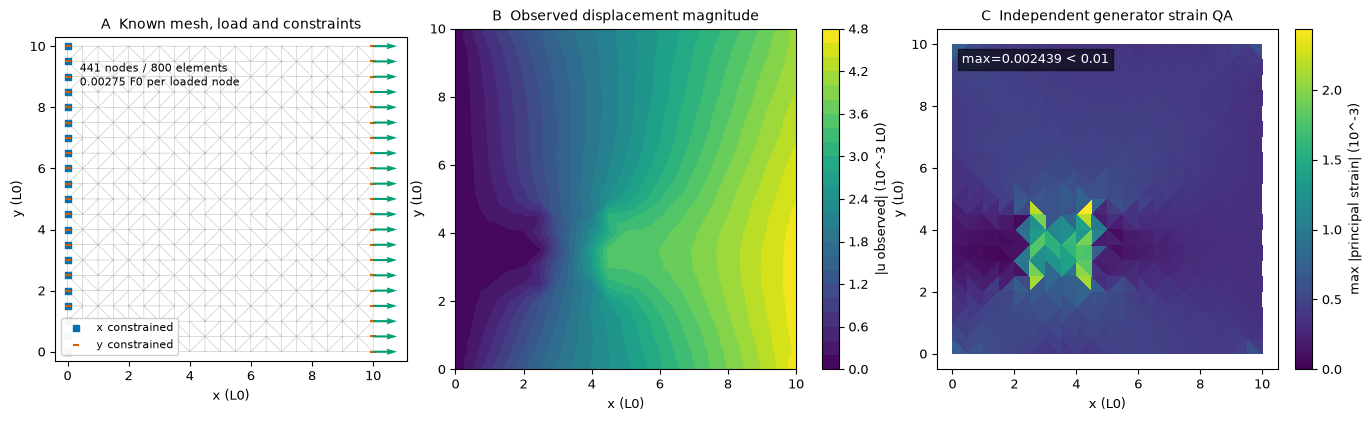

02_original_and_fresh_methods


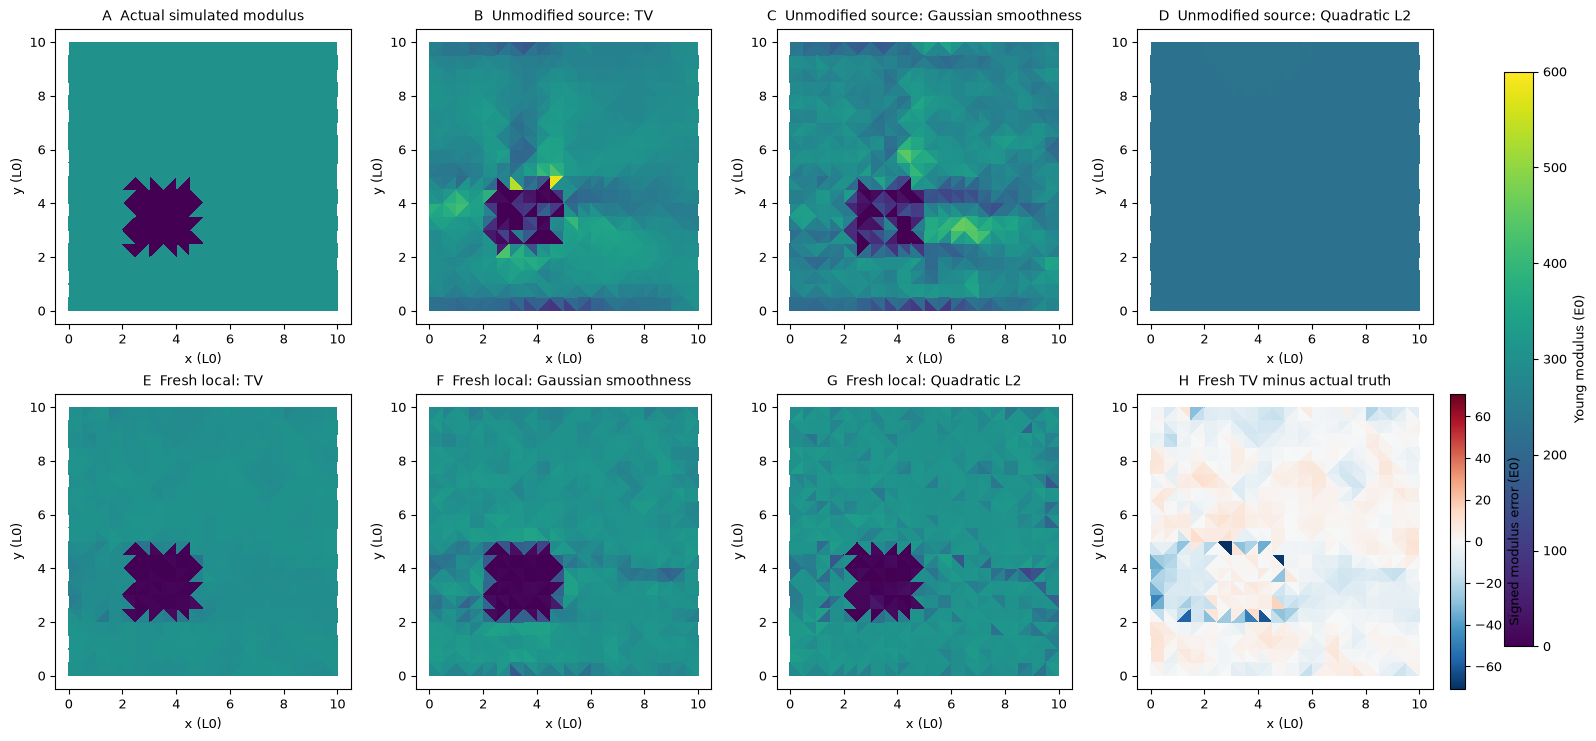

03_qualified_parity_and_metrics


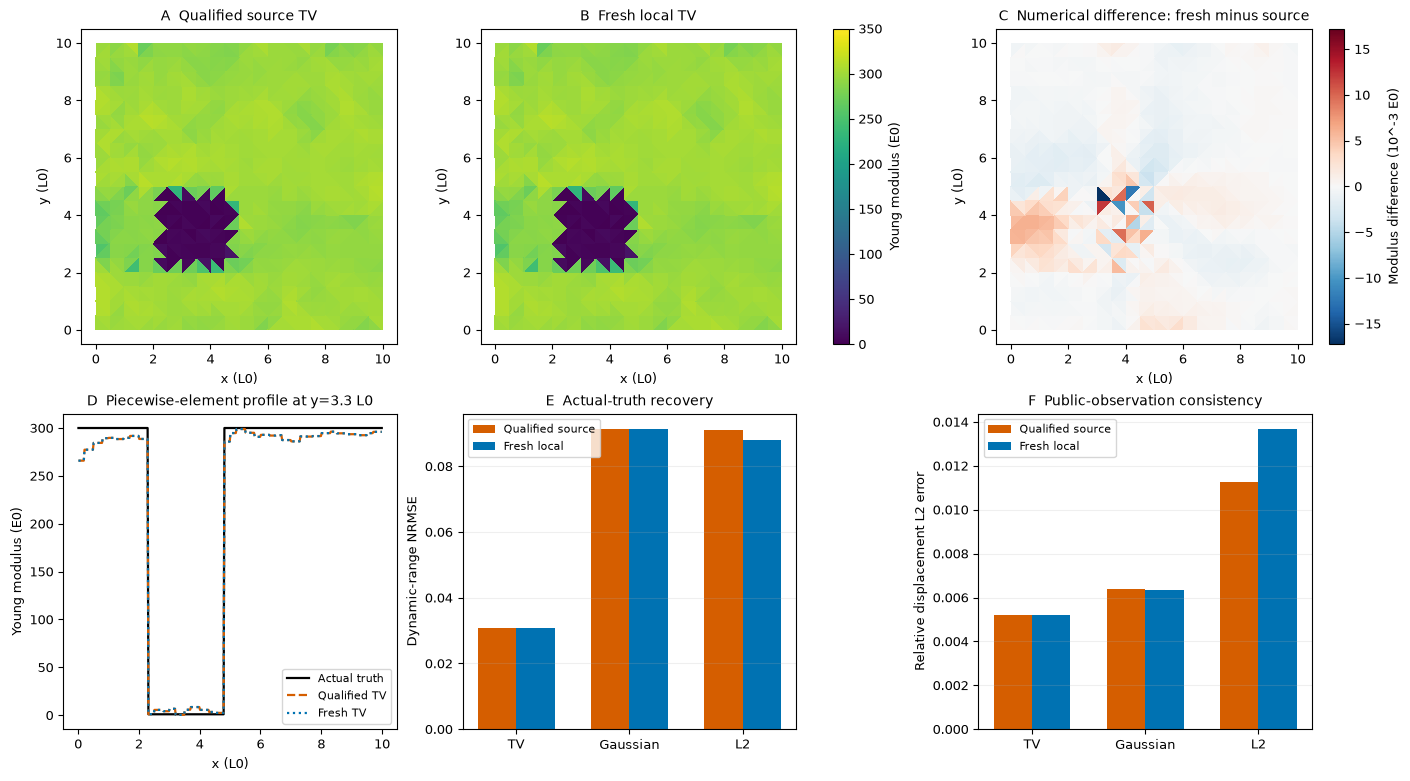

04_convergence_and_actual_stops


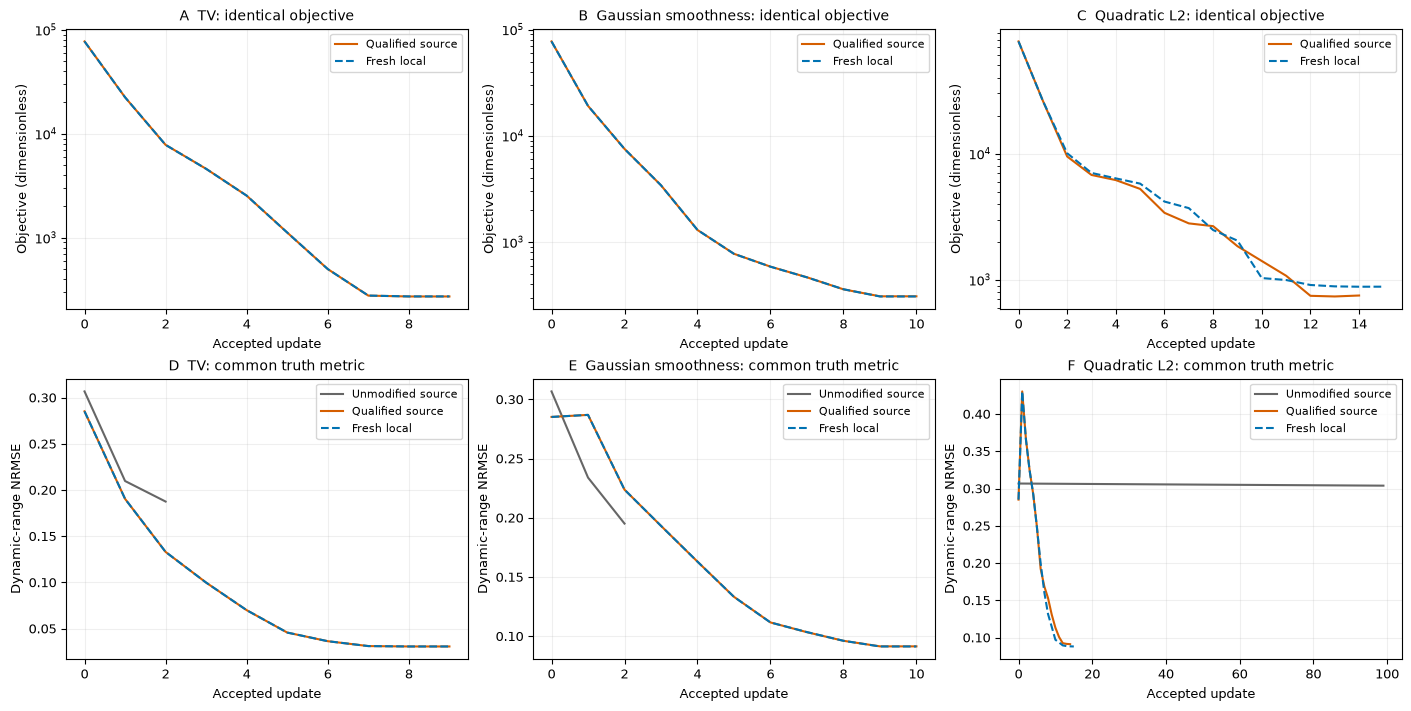

05_observation_fits_and_noise


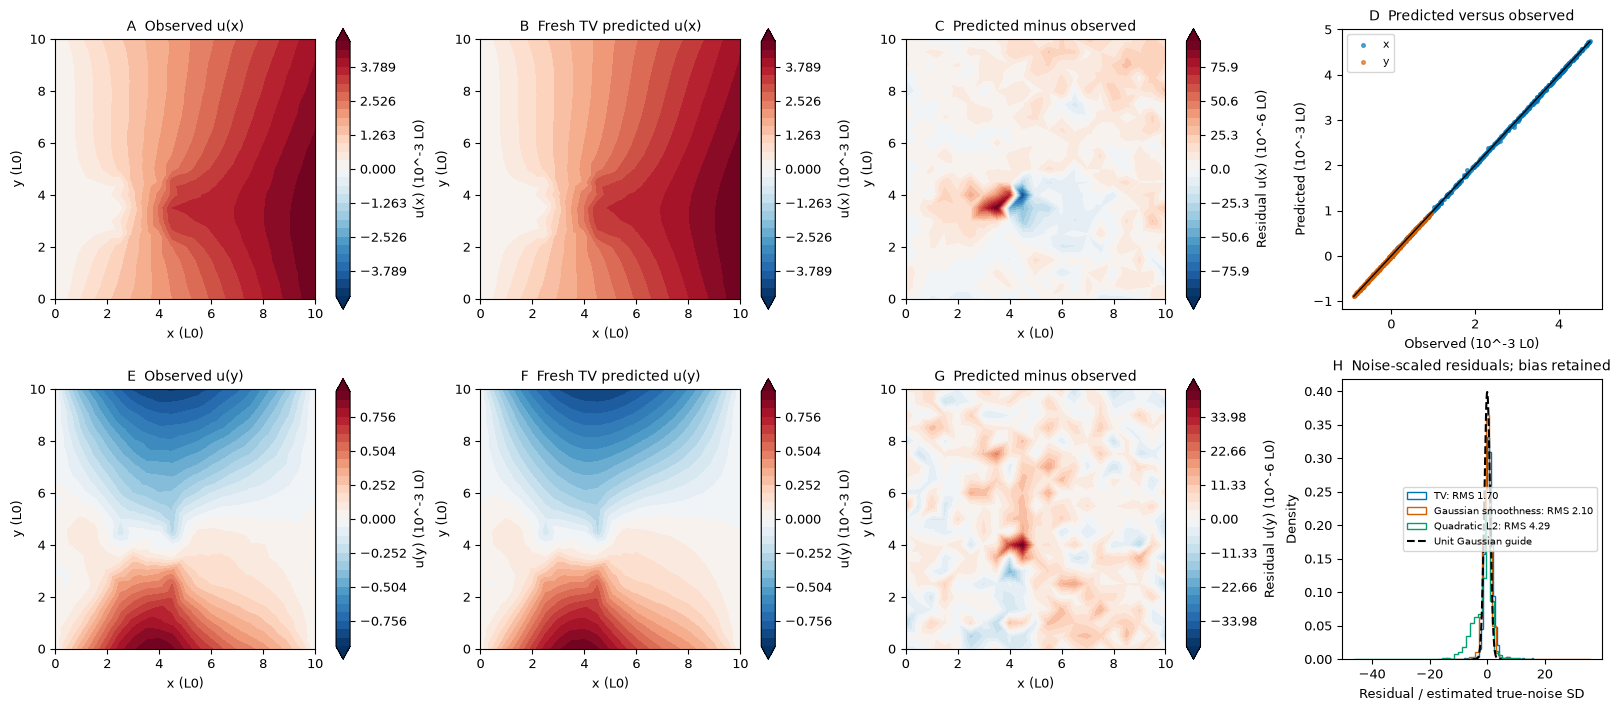

06_sensitivity_and_independent_physics


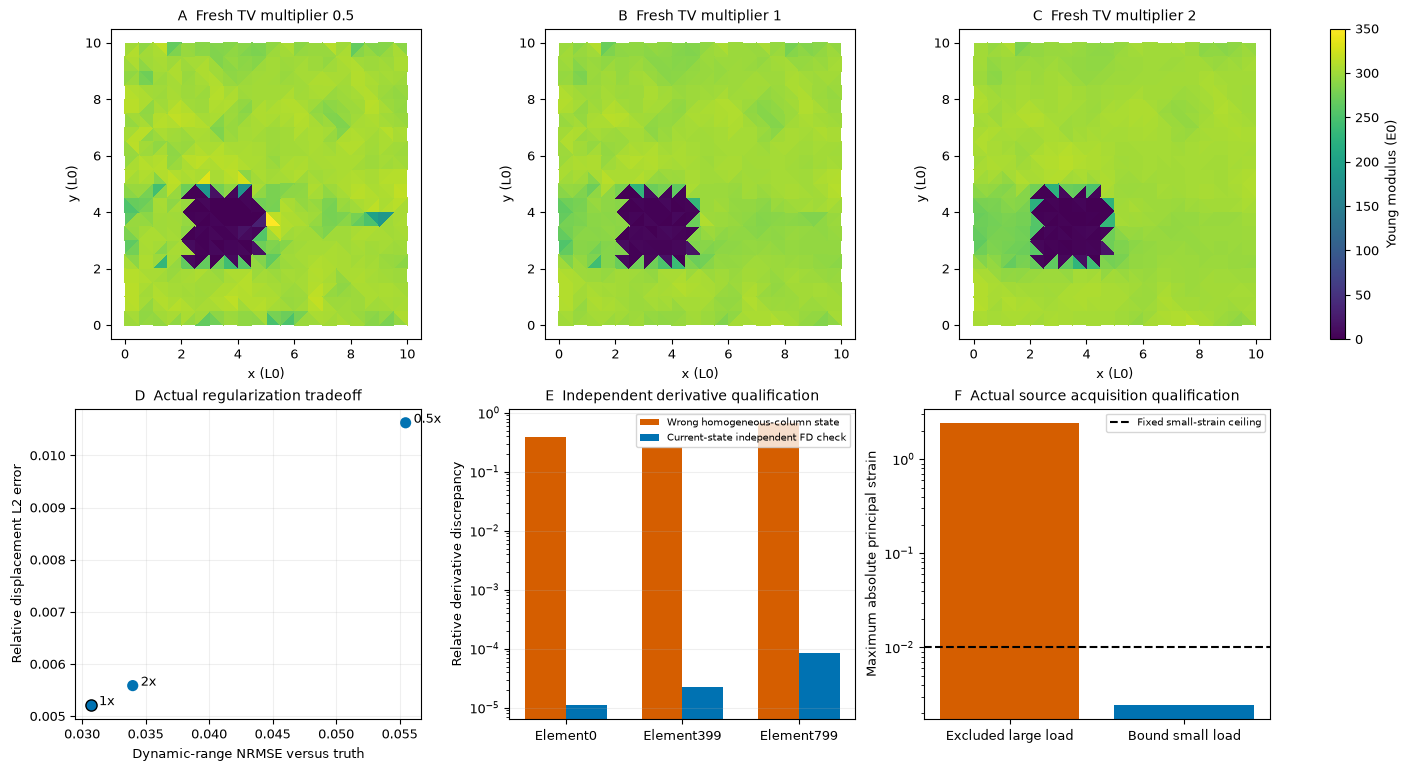

Exported six PNG/SVG/PDF groups with numeric sources: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch5_20261021\bio_med_mechanics\figures\plane_stress_elasticity_tomography


In [5]:
figures=make_figures(acquisition,truth,original,qualified,fresh,sensitivity,diagnostics)
numeric={'nodes':acquisition.nodes,'triangles':acquisition.triangles,'observed_displacement':acquisition.displacement,'truth':truth,**diagnostics}
for prefix,group in (('original',original),('qualified',qualified)):
    for method,result in group.items():
        for key,value in result.items():numeric[prefix+'_'+method+'_'+key]=value
for method,result in fresh.items():
    for key in ('reconstruction','modulus_history','objective_history','predicted_displacement','step_sizes','directions'):
        numeric['fresh_'+method+'_'+key]=getattr(result,key)
for multiplier,result in sensitivity.items():numeric['sensitivity_'+str(multiplier)]=result.reconstruction
metadata={'data_sha256':raw_hash,'active_seconds':active_seconds,'fresh_metrics':quality,'fresh_runs':{m:{'runtime_seconds':r.runtime_seconds,'updates':len(r.step_sizes),'stop':r.stop_reason} for m,r in fresh.items()},'figure_sources':{name:list(numeric) for name in figures}}
figure_directory=Path(os.environ['IMAGING101_FIGURE_DIR'])
manifest=export_figures(figures,figure_directory,numeric,metadata)
for name,figure in figures.items():
    print(name);display(figure);plt.close(figure)
print('Exported six PNG/SVG/PDF groups with numeric sources:',figure_directory)

## 6. Conclusion

The retained truth, full-parameter, independent equilibrium/energy/derivative and strain checks support the qualified small-load inverse. Ad-hoc weighting does not establish calibrated chi-square statistics, and performance at the excluded large strain is not validated.

### Interpretation and limits

The selected TV reconstruction must pass the independent four-metric Judge. The other priors and TV strengths remain explicitly labeled scientific comparisons; missing or poor methods are never replaced. Strong truth recovery and the small-strain gate support this particular bound simulation, not a claim of clinical or SI-calibrated material accuracy. The author-defined phantom, known boundary/load assumptions, source penalty convention, and observation-based ad-hoc weights limit generalization. Original Octave lifecycle failures, complete-state recovery, independent backend variation, and all mathematical qualifications are recorded in the authoritative validation report.

### Observed comparison-method numerical limitation

The complete qualified L2 source stops after14 accepted updates; fresh local L2 stops after15, both retaining the final increase-triggered field. Source/fresh dynamic-range NRMSE are 0.0911564443353/0.0881058767101, and observation-relative L2 errors are 0.0112502139656/0.0136906192705. These are actual different outcomes, not a claim that L2 passes the TV-specific full-pipeline numerical tolerance. L2 is a scientific comparison method; the standard evaluated method is TV.

At the same fixed source material field, independently replayed local GN using the captured source Jacobian and source prediction agrees with the source direction to7.07e-10 relative. At the first heterogeneous update, the weighted GN system condition number is1.047e9; source/local finite-difference Jacobians differ1.95e-6 relative and their directions1.03e-4, while forward displacement differs1.11e-14. This localizes sensitivity to cancellation in the source's tiny absolute central-difference step followed by an ill-conditioned inverse update, with perturbations accumulating across different states. The original step, cap, weak L2 prior and final field were retained rather than adjusted to force agreement. Complete fixed-field source/local line-search evidence is in the private archive and validation report.

The six plots retain all actual histories, including the original L2's99 updates and qualified/fresh14/15 updates. Quality of all three fresh methods is reported; only the selected TV is required to meet the declared standard-method Judge thresholds.
